# Channel importance and activation performance

In [1]:
%matplotlib inline
from pathlib import Path
import json
import cloudpickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score

ROOT = Path.cwd()
if not (ROOT / "environment.yml").is_file():
    ROOT = ROOT.parent
assert (ROOT / "environment.yml").is_file(), "Open the project root or this notebook folder."
OUTPUT = ROOT / "results/feature_importance"
OUTPUT.mkdir(parents=True, exist_ok=True)
REPEATS, SEED = 30, 42
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
def load_data(folder, filename):
    path = ROOT / "results" / folder
    with (path / filename).open("rb") as file:
        artifact = cloudpickle.load(file)
    rows = pd.read_csv(path / "epoch_split.csv")
    saved = pd.read_csv(path / "test_predictions.csv")
    with np.load(path / "epochs.npz") as data:
        X, y, trials, channels = data["X"], data["y"], data["trial"], data["channels"].tolist()
        np.testing.assert_array_equal(data["trial"], rows["trial"])
        np.testing.assert_array_equal(data["split"], rows["split"])
        assert float(data["sfreq"]) == artifact["preprocessing"]["sample_rate_hz"]
    assert channels == artifact["channels"] and list(X.shape[1:]) == artifact["input_shape"]
    assert np.isfinite(X).all() and artifact["input_units"] == "microvolts"
    test = rows["split"].eq("Test").to_numpy()
    np.testing.assert_array_equal(rows.loc[test, ["trial", "event_id"]], saved[["trial", "event_id"]])
    np.testing.assert_array_equal(y[test], saved["label"])
    pipeline = artifact["pipeline"]
    features = pipeline[0].transform(X)
    np.testing.assert_array_equal(pipeline[1:].predict(features[test]), saved["predicted"])
    np.testing.assert_allclose(pipeline[1:].predict_proba(features[test])[:, 1], saved["score"])
    return dict(model=pipeline[1:], features=features, y=y, trials=trials, test=test,
                channels=channels, rows=rows, saved=saved, source=str(path.relative_to(ROOT)))

In [3]:
models = {
    "Activation": load_data("hackathon_pipeline", "activate_classifier.pkl"),
    "Double blink": load_data("blink_pipeline_all_channels", "blink_classifier.pkl"),
}
assert all(len(data["channels"]) == 21 for data in models.values())
display(pd.DataFrame([{"Model": name, "Channels": len(data["channels"]),
                       "Features": data["features"].shape[1], "Test epochs": int(data["test"].sum())}
                      for name, data in models.items()]))

,Model,Channels,Features,Test epochs
0,Activation,21,105,234
1,Double blink,21,420,89


In [4]:
def channel_importance(data):
    X, y = data["features"][data["test"]], data["y"][data["test"]]
    model = data["model"]
    baseline = balanced_accuracy_score(y, model.predict(X))
    width = X.shape[1] // len(data["channels"])
    rng = np.random.default_rng(SEED)
    orders = [rng.permutation(len(X)) for _ in range(REPEATS)]
    rows = []
    for i, channel in enumerate(data["channels"]):
        columns = np.arange(i * width, (i + 1) * width)
        for repeat, order in enumerate(orders, 1):
            shuffled = X.copy()
            shuffled[:, columns] = X[order][:, columns]
            drop = 100 * (baseline - balanced_accuracy_score(y, model.predict(shuffled)))
            rows.append({"Channel": channel, "Repeat": repeat, "Drop (pp)": drop})
    repeats = pd.DataFrame(rows)
    ranking = repeats.groupby("Channel", sort=False)["Drop (pp)"].agg(["mean", lambda x: np.std(x)])
    ranking.columns = ["Mean drop (pp)", "SD (pp)"]
    return ranking.reset_index().sort_values("Mean drop (pp)", ascending=False, kind="stable"), repeats

Activation
Double blink


,Channel,Mean drop (pp),SD (pp)
0,C4,17.57,2.99
1,p8,12.03,1.96
2,p3,9.80,1.97
3,F10,9.02,1.97
4,o1,7.01,1.51
5,F9,3.94,1.66
6,pz,3.88,0.93
7,p4,3.12,1.46
8,p7,2.70,1.34
9,C3,2.19,1.53


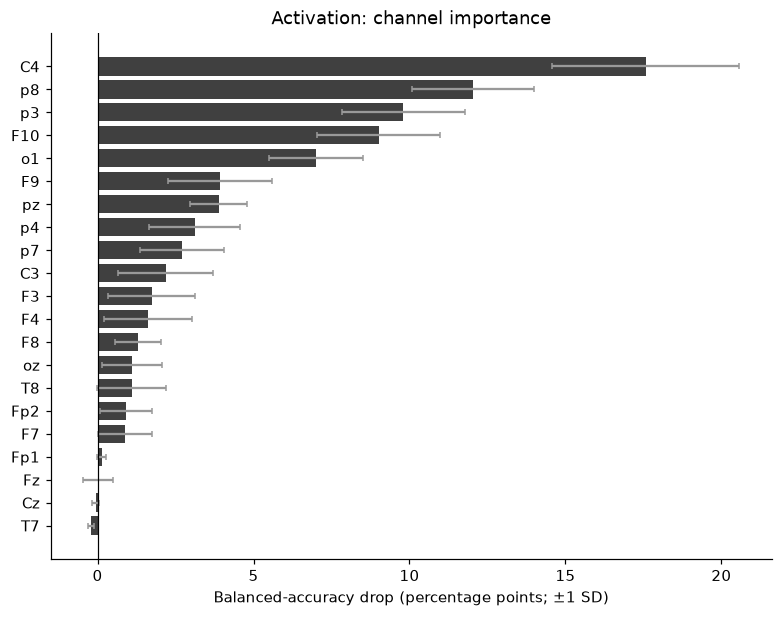

,Channel,Mean drop (pp),SD (pp)
0,Fp2,4.55,1.69
1,Fp1,4.29,1.52
2,F4,0.20,0.52
3,F9,0.00,0.00
4,F7,0.00,0.00
5,F3,0.00,0.00
6,Fz,0.00,0.00
7,F8,0.00,0.00
8,F10,0.00,0.00
9,T7,0.00,0.00


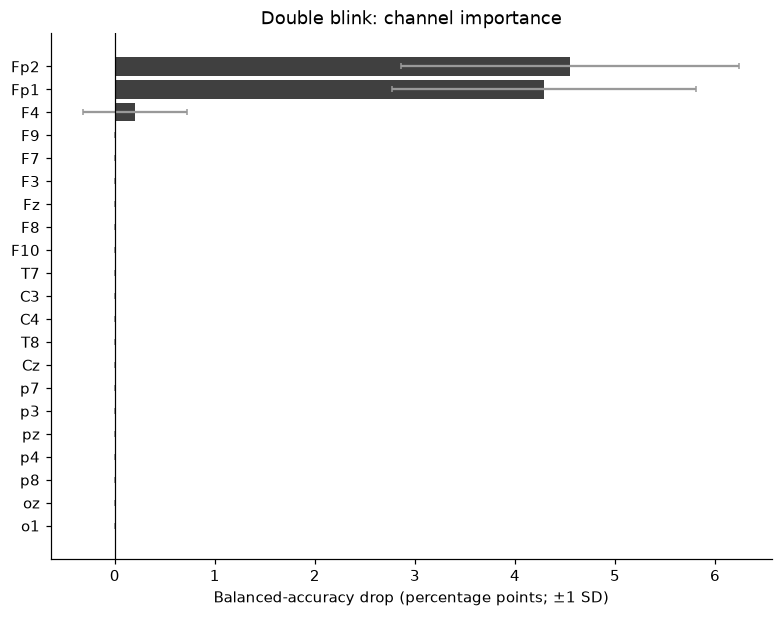

In [5]:
for name, data in models.items():
    ranking, repeats = channel_importance(data)
    data["ranking"] = ranking
    prefix = name.lower().replace(" ", "_")
    ranking.to_csv(OUTPUT / f"{prefix}_channel_ranking.csv", index=False)
    repeats.to_csv(OUTPUT / f"{prefix}_channel_repeats.csv", index=False)
    print(name)
    display(ranking.reset_index(drop=True).round(2))
    table = ranking.iloc[::-1]
    fig, ax = plt.subplots(figsize=(7, 5.5), layout="constrained")
    ax.barh(table["Channel"], table["Mean drop (pp)"], xerr=table["SD (pp)"], color="0.25", ecolor="0.6", capsize=2)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set(title=f"{name}: channel importance", xlabel="Balanced-accuracy drop (percentage points; ±1 SD)")
    fig.savefig(OUTPUT / f"{prefix}_channels.png", dpi=160)
    plt.show()

In [6]:
activation = models["Activation"]
X, y = activation["features"], activation["y"]
channels = np.array(activation["channels"])
ranked_channels = tuple(activation["ranking"]["Channel"])
train = np.isin(activation["trials"], [1, 2, 3, 4])
test = activation["trials"] == 5
assert X.shape == (772, 105) and train.sum() == 538 and test.sum() == 234
assert not (train & test).any() and (train | test).all()
np.testing.assert_array_equal(test, activation["test"])
print("Fit: Trials 1–4. Explore: Trial 5. Counts describe model inputs; preprocessing uses all 21 channels.")

Fit: Trials 1–4. Explore: Trial 5. Counts describe model inputs; preprocessing uses all 21 channels.


In [7]:
metrics, predictions, subsets = [], [], []
for count in range(1, 22):
    selected = np.isin(channels, ranked_channels[:count])
    columns = np.flatnonzero(np.repeat(selected, 5))
    assert len(columns) == 5 * count and (not subsets or set(subsets[-1]) <= set(columns))
    subsets.append(columns)
    model = clone(activation["model"]).fit(X[train][:, columns], y[train])
    predicted = model.predict(X[test][:, columns])
    scores = model.predict_proba(X[test][:, columns])[:, 1]
    metrics.append({"Channel count": count, "Added channel": ranked_channels[count - 1],
                    "Channels": ", ".join(channels[selected]), "Accuracy": accuracy_score(y[test], predicted),
                    "Balanced accuracy": balanced_accuracy_score(y[test], predicted),
                    "Precision": precision_score(y[test], predicted, zero_division=0),
                    "Recall": recall_score(y[test], predicted, zero_division=0),
                    "F1": f1_score(y[test], predicted, zero_division=0)})
    rows = activation["rows"].loc[test, ["trial", "event_id", "label", "stimulus_type"]].copy()
    predictions.append(rows.assign(channel_count=count, predicted=predicted, score=scores))
np.testing.assert_array_equal(predicted, activation["saved"]["predicted"])
np.testing.assert_allclose(scores, activation["saved"]["score"])
comparison = pd.DataFrame(metrics)

Channel count,Added channel,Accuracy,Balanced accuracy,Precision,Recall,F1
1,C4,90.6%,86.1%,60.0%,80.0%,68.6%
2,p8,94.0%,88.0%,75.0%,80.0%,77.4%
3,p3,94.9%,91.4%,76.5%,86.7%,81.2%
4,F10,96.2%,93.5%,81.8%,90.0%,85.7%
5,o1,95.7%,93.3%,79.4%,90.0%,84.4%
6,F9,95.7%,91.9%,81.2%,86.7%,83.9%
7,pz,96.2%,93.5%,81.8%,90.0%,85.7%
8,p4,96.2%,93.5%,81.8%,90.0%,85.7%
9,p7,96.2%,93.5%,81.8%,90.0%,85.7%
10,C3,96.6%,95.2%,82.4%,93.3%,87.5%


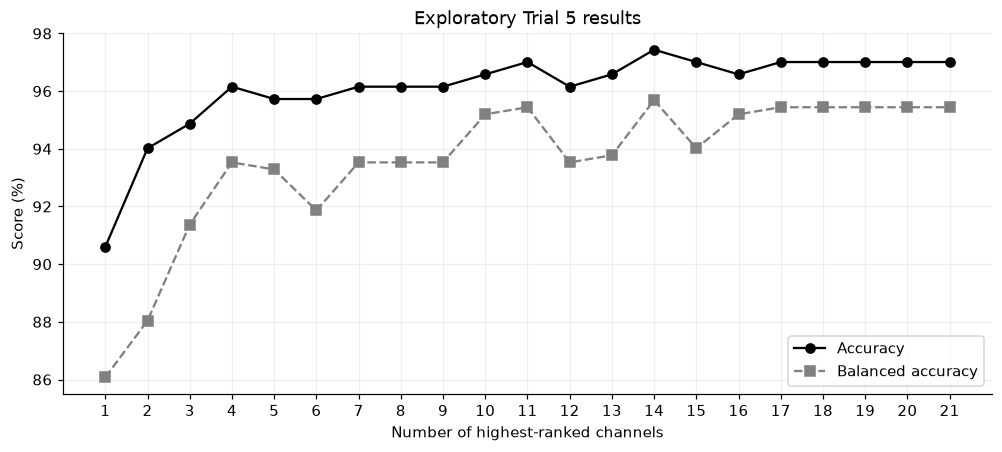

In [10]:
scores_to_show = ["Accuracy", "Balanced accuracy", "Precision", "Recall", "F1"]
display(comparison.drop(columns="Channels").style.format({name: "{:.1%}" for name in scores_to_show}).hide(axis="index"))
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.plot(comparison["Channel count"], 100 * comparison["Accuracy"], "o-", color="black", label="Accuracy")
ax.plot(comparison["Channel count"], 100 * comparison["Balanced accuracy"], "s--", color="0.5", label="Balanced accuracy")
ax.set(title="Exploratory Trial 5 results", xlabel="Number of highest-ranked channels", ylabel="Score (%)",
       xticks=range(1, 22))
ax.grid(alpha=0.2)
ax.legend()
fig.savefig(OUTPUT / "activation_channel_sweep.png", dpi=160)
plt.show()

In [9]:
comparison.to_csv(OUTPUT / "activation_channel_sweep.csv", index=False)
pd.concat(predictions, ignore_index=True).to_csv(OUTPUT / "activation_channel_sweep_predictions.csv", index=False)
metadata = {"ranking": "Trial-specific grouped permutation importance; balanced accuracy drop",
            "repeats": REPEATS, "seed": SEED, "sources": {name: data["source"] for name, data in models.items()},
            "activation_train_trials": [1, 2, 3, 4], "activation_test_trial": 5,
            "activation_channel_order": list(ranked_channels), "features_per_channel": 5,
            "classifier_parameters": activation["model"][-1].get_params(),
            "interpretation": "Trial 5 supplies ranking and evaluation: exploratory, not an independent test estimate.",
            "preprocessing": "Existing 21-channel preprocessing retained; only model inputs are reduced."}
(OUTPUT / "metadata.json").write_text(json.dumps(metadata, indent=2) + "\n")
print(f"Saved rankings, comparison, predictions, and plots to {OUTPUT}.")

Saved rankings, comparison, predictions, and plots to results/feature_importance.
